# **Using "Pumpkin_Seeds_Dataset.xlsx"**

Pumpkin seeds dataset from Murat Koklu's dataset page (https://www.muratkoklu.com/datasets/), also on Kaggle.

Koklu, M., Sarigil, S., & Ozbek, O. (2021). The use of machine learning methods in classification of pumpkin seeds (Cucurbita pepo L.). Genetic Resources and Crop Evolution, 68(7), 2713-2726.

This dataset is computed from images of 2500 pumpkin seeds. Each seed was photographed and its shape was measured from the image.

The dataset comprises 12 features (Area, Perimeter, Major_Axis_Length, Minor_Axis_Length, Convex_Area, Equiv_Diameter, Eccentricity, Solidity, Extent, Roundness, Aspect_Ration, and Compactness) and a target (Class, the seed variety).

This data has two classes of pumpkin seed: Çerçevelik and Ürgüp Sivrisi, both grown in Turkey. Here, we build an SVM model to classify the variety of a seed just from its shape.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn import svm

from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix


In [2]:
#load the data (xlsx so we use read_excel instead of read_csv)
df=pd.read_excel('Pumpkin_Seeds_Dataset.xlsx')


Exploring Data. We check the features and target names.

In [3]:
#print the names of the 12 features
print("Features: ", df.drop('Class', axis=1).columns.tolist())

#print the label type of seed('Çerçevelik' 'Ürgüp Sivrisi')
print("Labels: ", df['Class'].unique().tolist())


Features:  ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Convex_Area', 'Equiv_Diameter', 'Eccentricity', 'Solidity', 'Extent', 'Roundness', 'Aspect_Ration', 'Compactness']
Labels:  ['Çerçevelik', 'Ürgüp Sivrisi']


In [4]:
#print data(features) shape
df.shape

(2500, 13)

In [5]:
#print the top 5 records
df.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Convex_Area,Equiv_Diameter,Eccentricity,Solidity,Extent,Roundness,Aspect_Ration,Compactness,Class
0,56276,888.242,326.1485,220.2388,56831,267.6805,0.7376,0.9902,0.7453,0.8963,1.4809,0.8207,Çerçevelik
1,76631,1068.146,417.1932,234.2289,77280,312.3614,0.8275,0.9916,0.7151,0.8440,1.7811,0.7487,Çerçevelik
2,71623,1082.987,435.8328,211.0457,72663,301.9822,0.8749,0.9857,0.7400,0.7674,2.0651,0.6929,Çerçevelik
3,66458,992.051,381.5638,222.5322,67118,290.8899,0.8123,0.9902,0.7396,0.8486,1.7146,0.7624,Çerçevelik
4,66107,998.146,383.8883,220.4545,67117,290.1207,0.8187,0.9850,0.6752,0.8338,1.7413,0.7557,Çerçevelik


In [6]:
#count of each seed type, pretty balanced so we dont need to worry about one class taking over
print(df['Class'].value_counts())

#check for missing values
print("\nMissing values: ", df.isna().sum().sum())

Class
Çerçevelik       1300
Ürgüp Sivrisi    1200
Name: count, dtype: int64

Missing values:  0


In [7]:
#look at the scale of each feature
#Area is in the 10,000s while Eccentricity is under 1, so we need to scale before SVM
df.describe().T[['mean','std','min','max']]

,mean,std,min,max
Area,80658.220800,13664.510228,47939.0000,136574.0000
Perimeter,1130.279015,109.256418,868.4850,1559.4500
Major_Axis_Length,456.601840,56.235704,320.8446,661.9113
Minor_Axis_Length,225.794921,23.297245,152.1718,305.8180
Convex_Area,81508.084400,13764.092788,48366.0000,138384.0000
Equiv_Diameter,319.334230,26.891920,247.0584,417.0029
Eccentricity,0.860879,0.045167,0.4921,0.9481
Solidity,0.989492,0.003494,0.9186,0.9944
Extent,0.693205,0.060914,0.4680,0.8296
Roundness,0.791533,0.055924,0.5546,0.9396


Preparing Data. SVM only works with numbers, so the seed names get turned into 0 and 1 with LabelEncoder. SVM is also sensitive to the size of the numbers, so StandardScaler puts every feature on the same scale.

In [8]:
#encode the class names into numbers
le_class=LabelEncoder()
df['Class']=le_class.fit_transform(df['Class'])

#check which number is which seed (0:Çerçevelik, 1:Ürgüp Sivrisi)
print(dict(zip(le_class.classes_, le_class.transform(le_class.classes_))))


{'Çerçevelik': np.int64(0), 'Ürgüp Sivrisi': np.int64(1)}


In [9]:
#split between features as X and target as y
X=df.drop('Class', axis=1)
y=df['Class']


Splitting Data. Split the dataset into a training set and a test set with train_test_split(). 70% training and 30% test, random_state so we get the same split every time.

In [10]:
#split dataset into training set and test set 30%
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.3, random_state=109)

#apply StandardScaler, fit only on the train set so the test set stays unseen
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


Generating Model. First we try the linear kernel like the breast cancer example.

In [11]:
#create a svm classifier
clf=svm.SVC(kernel='linear') #Linear Kernel

#train the model using the training sets
clf.fit(X_train, y_train)

#predict the response for test dataset
y_pred=clf.predict(X_test)


Evaluating the Model. Accuracy is computed by comparing actual test set values and predicted values.

In [12]:
#model accuracy: how often is the classifier correct?
print("Accuracy: ", metrics.accuracy_score(y_test, y_pred))

Accuracy:  0.8853333333333333


In [13]:
#model precision: of the seeds predicted Ürgüp Sivrisi, how many actually were?
print("Precision: ", metrics.precision_score(y_test, y_pred))

#model recall: of the real Ürgüp Sivrisi seeds, how many did we catch?
print("Recall: ", metrics.recall_score(y_test, y_pred))

#f1 score: balance of precision and recall
print("F1-Score: ", metrics.f1_score(y_test, y_pred))


Precision:  0.9262536873156342
Recall:  0.8373333333333334


F1-Score:  0.8795518207282913


In [14]:
#generate the classification report for both classes
report=classification_report(y_test, y_pred, target_names=le_class.classes_)
print("\nClassification Report:\n", report)


Classification Report:
                precision    recall  f1-score   support

   Çerçevelik       0.85      0.93      0.89       375
Ürgüp Sivrisi       0.93      0.84      0.88       375

     accuracy                           0.89       750
    macro avg       0.89      0.89      0.89       750
 weighted avg       0.89      0.89      0.89       750



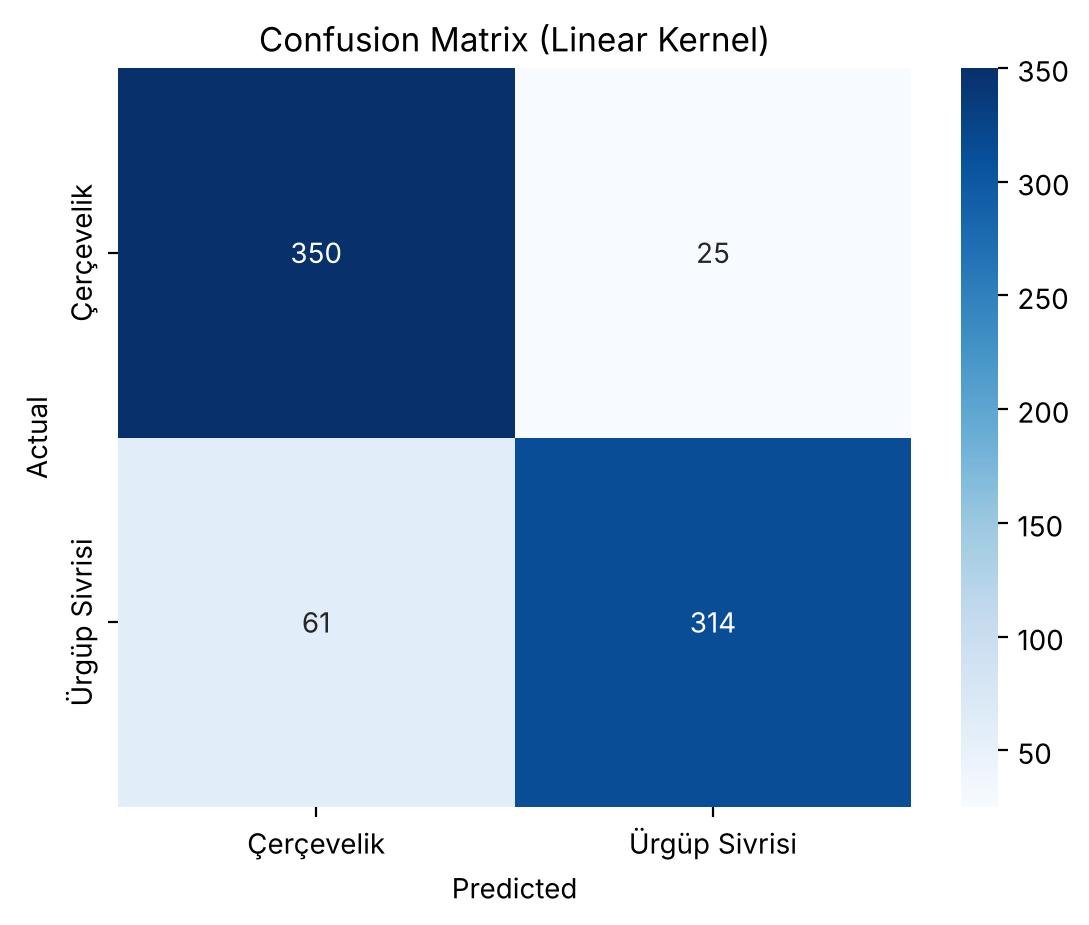

In [15]:
#confusion matrix to see where the mistakes are
cm=confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le_class.classes_, yticklabels=le_class.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Linear Kernel)')
plt.show()

Trying another kernel. The advertising example used the default SVC() which is the RBF kernel. Lets see if a curved boundary does better than a straight line.

In [16]:
#create a svm classifier with the default rbf kernel
clf_rbf=svm.SVC(kernel='rbf')

#train and predict
clf_rbf.fit(X_train, y_train)
y_pred_rbf=clf_rbf.predict(X_test)

#compare the two kernels
print("Linear Accuracy: ", metrics.accuracy_score(y_test, y_pred))
print("RBF Accuracy: ", metrics.accuracy_score(y_test, y_pred_rbf))
print("\nClassification Report (RBF):\n", classification_report(y_test, y_pred_rbf, target_names=le_class.classes_))


Linear Accuracy:  0.8853333333333333
RBF Accuracy:  0.8893333333333333

Classification Report (RBF):
                precision    recall  f1-score   support

   Çerçevelik       0.85      0.94      0.89       375
Ürgüp Sivrisi       0.93      0.84      0.88       375

     accuracy                           0.89       750
    macro avg       0.89      0.89      0.89       750
 weighted avg       0.89      0.89      0.89       750



Predicting a new seed. All 12 features are numbers here so there is no country/city encoding problem like the advertising example. The function scales the new values with the same scaler and decodes the prediction back to the seed name.

In [17]:
#predict the seed type for new measurements
def predict_seed(new_seed):
  #new_seed is a list of the 12 features in the same order as X.columns
  new_df=pd.DataFrame([new_seed], columns=X.columns)

  #scale with the same scaler used on the training data
  new_scaled=scaler.transform(new_df)

  #predict and turn the 0/1 back into the seed name
  prediction=clf.predict(new_scaled)[0]
  return le_class.inverse_transform([prediction])[0]


#example: measurements of a seed (first row of the original data, its a Çerçevelik)
new_seed=[56276, 888.242, 326.1485, 220.2388, 56831, 267.6805, 0.7376, 0.9902, 0.7453, 0.8963, 1.4809, 0.8207]
print("Prediction: ", predict_seed(new_seed))


Prediction:  Çerçevelik


## Explaining the Results

So basically I gave the computer measurements of 2500 pumpkin seeds (how big they are, how long, how round, etc.) and told it which of the 2 types each seed was. Then it learned how to tell them apart. I hid 30% of the seeds (750) while it was learning and then tested it on those to see how it does on seeds it never saw.

How SVM works in simple terms: imagine every seed is a dot on a graph. SVM draws a line between the 2 groups of dots and tries to make the gap on both sides as wide as possible. Then a new seed just gets labeled based on which side of the line it lands on.

Results:
- the straight line version (linear kernel) got about 88.5% of the seeds right, and the curved version (RBF kernel) got 88.9%. so the curve barely helped, which means a straight line already does most of the job here
- out of 375 Çerçevelik seeds it got 350 right (93%), and out of 375 Ürgüp Sivrisi seeds it got 314 right (84%)
- when it says a seed is Ürgüp Sivrisi its almost always right (93% precision), but it misses some of them and calls them Çerçevelik instead

Why its not 100%: some seeds from the 2 types just look really similar. like a long Çerçevelik and a short Ürgüp Sivrisi can have almost the same shape, so no line can split them perfectly if all we have is shape.

Does it match the research? yes, the original paper (Koklu et al., 2021) got 88.64% with SVM on the same data, which is basically what I got.

Why it matters: sorting seeds by hand takes forever. with a camera and a model like this you could sort them automatically and get it right about 9 out of 10 times.